# MARIO matching and integration pipeline

This tutorial will guide you through a list of general steps to perform matching and integration of single cell proteomic datasets. For R usesers please refer to the R tutorial for MARIO.

This script will include matching and integration of two or more then two datasets. First we will start with analysis on bone marrow cells [cite-seq](https://satijalab.org/seurat/articles/multimodal_reference_mapping.html#example-2-mapping-human-bone-marrow-cells-1) and [cytof](https://github.com/lmweber/benchmark-data-Levine-32-dim) cells. The data is same as we presented in the [paper](https://www.google.com/webhp?hl=en&ictx=2&sa=X&ved=0ahUKEwjdv9mYldfyAhUrJTQIHS4jBcQQPQgJ). First we load up MARIO in python:


In [1]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import os

from matplotlib.ticker import MaxNLocator

from mario.match import Mario # main object
from mario.match_utils import eval_matching_accuracy # for evaluating matching accuracy
from mario.match import pipelined_mario # for running the overall pipeline

## 1. Read in data and structure

We read in the two datasets, both protein features, with row as cells and column with features: overlapping or non-overlapping protein types (remember to make sure overlapping proteins have the same name accross datasets). Here the two datasets we used also contains a column of cell IDs and a column of cell types. These are **optional** and will not affect the **MARIO** mathcing and integration.

**Note**: *If there exists inner sturcture of rows and cell types in the dataset (eg. an imaging data where row 1 - row 5000 are all B cells due to same FOV of germinal center) the best practice is to randomnize the rows before matching, as extremely unbalanced cell population when running in certain parameters (high ```batches```) can sometimes give sub-optimal results.*

In [2]:
def process_species_data(qbc_path, cytof_path, species='human'):
    """
    Process and prepare data for a single species (human or rhesus) for MARIO matching.
    MARIO-ready data will contain all features except metadata columns.
    
    Parameters:
    - qbc_path: path to QBC dataset
    - cytof_path: path to CyTOF dataset
    - species: 'human' or 'rhesus'
    
    Returns:
    - Dictionary containing processed dataframes and metadata
    """
    # Load complete datasets
    qbc_full = pd.read_csv(qbc_path)
    cytof_full = pd.read_csv(cytof_path)
    
    print(f"\nProcessing {species} datasets:")
    print(f"QBC shape: {qbc_full.shape}")
    print(f"CyTOF shape: {cytof_full.shape}")
    
    # Define metadata columns
    metadata_cols = {
        'QBC': ['donor', 'QBC_annotation'],
        'CyTOF': ['donor', 'CyTOF_annotation', 'stimulation']
    }
    
    # Get all feature columns (excluding metadata)
    qbc_features = qbc_full.columns.difference(metadata_cols['QBC'])
    cytof_features = cytof_full.columns.difference(metadata_cols['CyTOF'])
    
    # Create MARIO-ready datasets with all features (excluding metadata)
    qbc_mario = qbc_full[qbc_features].copy()
    cytof_mario = cytof_full[cytof_features].copy()
    
    print(f"\n{species.capitalize()} dataset features:")
    print(f"QBC features: {len(qbc_features)}")
    print(f"CyTOF features: {len(cytof_features)}")
    
    # Verify shapes of MARIO-ready data
    print(f"\n{species.capitalize()} MARIO-ready shapes:")
    print(f"QBC: {qbc_mario.shape}")
    print(f"CyTOF: {cytof_mario.shape}")
    
    return {
        'mario_data': {
            'QBC': qbc_mario,
            'CyTOF': cytof_mario
        },
        'full_data': {
            'QBC': qbc_full,
            'CyTOF': cytof_full
        },
        'feature_cols': {
            'QBC': qbc_features,
            'CyTOF': cytof_features
        },
        'metadata_cols': metadata_cols
    }

In [3]:
def prepare_for_mario(human_data, rhesus_data=None):
    """
    Prepare processed data for MARIO matching.
    
    Parameters:
    - human_data: Dictionary containing processed human data
    - rhesus_data: Optional dictionary containing processed rhesus data
    
    Returns:
    - Dictionary containing MARIO-ready datasets and metadata
    """
    mario_data = {
        'human': {
            'mario_ready': {
                'QBC': human_data['mario_data']['QBC'].values,
                'CyTOF': human_data['mario_data']['CyTOF'].values
            },
            'full_data': human_data['full_data'],
            'feature_cols': human_data['feature_cols'],
            'metadata_cols': human_data['metadata_cols']
        }
    }
    
    if rhesus_data is not None:
        mario_data['rhesus'] = {
            'mario_ready': {
                'QBC': rhesus_data['mario_data']['QBC'].values,
                'CyTOF': rhesus_data['mario_data']['CyTOF'].values
            },
            'full_data': rhesus_data['full_data'],
            'feature_cols': rhesus_data['feature_cols'],
            'metadata_cols': rhesus_data['metadata_cols']
        }
    
    return mario_data

In [4]:
#Load data
# *Clean up .csv files. Column names should only be marker names, and donor, cluster annotation
# *Make sure that: for the same feature/marker, the feature/marker name is SAME in both .csv files in order to match

# Define your paths
paths = {
    'human': {
        'qbc': "C:/Users/Aaron/Nolan Lab Dropbox/Aaron Tan/QBC/Seurat_QBC_clustering/export_QBC_annotated_data_10k_cells_each/QBC_Human_combined.csv",
        'cytof': "C:/Users/Aaron/Nolan Lab Dropbox/Aaron Tan/QBC/Seurat_CyTOF_clustering/Bjornson_Stimulations/exported_data/human_balanced_36k_cells.csv"
    },
    'rhesus': {
        'qbc': "C:/Users/Aaron/Nolan Lab Dropbox/Aaron Tan/QBC/Seurat_QBC_clustering/export_QBC_annotated_data_10k_cells_each/QBC_Rhesus_combined.csv",
        'cytof': "C:/Users/Aaron/Nolan Lab Dropbox/Aaron Tan/QBC/Seurat_CyTOF_clustering/Bjornson_Stimulations/exported_data/rhesus_balanced_36k_cells.csv"
    }
}

# Process human data
human_processed = process_species_data(
    paths['human']['qbc'],
    paths['human']['cytof'],
    species='human'
)

# Process rhesus data
rhesus_processed = process_species_data(
    paths['rhesus']['qbc'],
    paths['rhesus']['cytof'],
    species='rhesus'
)

# Prepare data for MARIO
mario_ready_data = prepare_for_mario(human_processed, rhesus_processed)


Processing human datasets:
QBC shape: (30000, 136)
CyTOF shape: (35880, 43)

Human dataset features:
QBC features: 134
CyTOF features: 40

Human MARIO-ready shapes:
QBC: (30000, 134)
CyTOF: (35880, 40)

Processing rhesus datasets:
QBC shape: (30000, 136)
CyTOF shape: (36000, 43)

Rhesus dataset features:
QBC features: 134
CyTOF features: 40

Rhesus MARIO-ready shapes:
QBC: (30000, 134)
CyTOF: (36000, 40)


In [5]:
# MARIO-ready data (without metadata)
human_qbc_mario = mario_ready_data['human']['mario_ready']['QBC']
human_cytof_mario = mario_ready_data['human']['mario_ready']['CyTOF']
rhesus_qbc_mario = mario_ready_data['rhesus']['mario_ready']['QBC']
rhesus_cytof_mario = mario_ready_data['rhesus']['mario_ready']['CyTOF']

# Full data (with metadata)
# From mario_ready_data
human_qbc_full = mario_ready_data['human']['full_data']['QBC']
human_cytof_full = mario_ready_data['human']['full_data']['CyTOF']
rhesus_qbc_full = mario_ready_data['rhesus']['full_data']['QBC']
rhesus_cytof_full = mario_ready_data['rhesus']['full_data']['CyTOF']

# Or from processed data directly
human_qbc_full_alt = human_processed['full_data']['QBC']
human_cytof_full_alt = human_processed['full_data']['CyTOF']
rhesus_qbc_full_alt = rhesus_processed['full_data']['QBC']
rhesus_cytof_full_alt = rhesus_processed['full_data']['CyTOF']

# Access metadata columns for human data
human_qbc_donors = human_qbc_full['donor']
human_qbc_annotations = human_qbc_full['QBC_annotation']
human_cytof_donors = human_cytof_full['donor']
human_cytof_annotations = human_cytof_full['CyTOF_annotation']
human_cytof_stimulation = human_cytof_full['stimulation']

# Access metadata columns for rhesus data
rhesus_qbc_donors = rhesus_qbc_full['donor']
rhesus_qbc_annotations = rhesus_qbc_full['QBC_annotation']
rhesus_cytof_donors = rhesus_cytof_full['donor']
rhesus_cytof_annotations = rhesus_cytof_full['CyTOF_annotation']
rhesus_cytof_stimulation = rhesus_cytof_full['stimulation']

# Access all features (replacing common_markers)
human_qbc_features = mario_ready_data['human']['feature_cols']['QBC']
human_cytof_features = mario_ready_data['human']['feature_cols']['CyTOF']
rhesus_qbc_features = mario_ready_data['rhesus']['feature_cols']['QBC']
rhesus_cytof_features = mario_ready_data['rhesus']['feature_cols']['CyTOF']

# Access metadata column definitions
human_metadata_cols = mario_ready_data['human']['metadata_cols']
rhesus_metadata_cols = mario_ready_data['rhesus']['metadata_cols']

In [6]:
# View the data
print("Human QBC MARIO-ready data (first 5 rows):")
print(human_qbc_mario[:5])  # For numpy arrays, use array slicing [:5] to view the first 5 rows of numpy arrays
print("\nHuman CyTOF full data head:")
print(human_cytof_full.head())  # For pandas DataFrames, use head()
print("\nRhesus QBC MARIO-ready data (first 5 rows):")
print(rhesus_qbc_mario[:5])
print("\nRhesus CyTOF full data head:")
print(rhesus_cytof_full.head())

# Check shapes
print("\nData shapes:")
print(f"Human QBC MARIO-ready: {human_qbc_mario.shape}") # For numpy arrays, use array slicing [:5] to view the first 5 rows of numpy arrays
print(f"Human QBC full: {human_qbc_full.shape}")          # pandas DataFrame shape
print(f"Human CyTOF MARIO-ready: {human_cytof_mario.shape}")
print(f"Human CyTOF full: {human_cytof_full.shape}")
print(f"Rhesus QBC MARIO-ready: {rhesus_qbc_mario.shape}")
print(f"Rhesus QBC full: {rhesus_qbc_full.shape}")
print(f"Rhesus CyTOF MARIO-ready: {rhesus_cytof_mario.shape}")
print(f"Rhesus CyTOF full: {rhesus_cytof_full.shape}")

Human QBC MARIO-ready data (first 5 rows):
[[1.37639436 0.44247891 0.74450167 1.71014952 1.28873797 2.09424923
  1.17131862 0.13027381 0.28697477 0.39154255 1.32637051 0.47665093
  1.6164269  0.70327663 0.50969371 1.50273568 1.68323059 0.45726727
  1.55468533 1.43697697 0.67218997 1.15926639 1.57888529 0.55950799
  1.90970996 0.92537445 0.2022634  0.57702419 0.8653942  0.11660921
  0.78761709 0.987734   0.62366932 0.08870676 1.14951891 0.37041863
  1.62254906 0.19592888 2.05145637 1.29298998 0.29275962 3.13816283
  0.22720765 1.73636276 0.0526969  0.66027873 0.87832405 2.34474543
  0.97323536 1.03000979 1.95995126 0.4814387  0.15705529 0.58135571
  0.39154255 0.08160778 1.795836   0.77701125 1.99630467 0.91304254
  1.13719942 0.74450167 0.56391589 0.26941669 0.759081   0.89108886
  0.00770029 1.04371367 2.8418815  0.94959121 0.0526969  0.02292524
  0.46214852 0.43750045 0.42746856 0.08870676 1.45698252 0.45726727
  0.43750045 0.57702419 0.50036379 0.70709538 0.08160778 0.15705529
  1.9

In [7]:
# Print the number of features in each dataset
print("\nNumber of features:")
print(f"Human QBC: {len(human_qbc_features)}")
print(f"Human CyTOF: {len(human_cytof_features)}")
print(f"Rhesus QBC: {len(rhesus_qbc_features)}")
print(f"Rhesus CyTOF: {len(rhesus_cytof_features)}")

# Print the shapes of MARIO-ready data
print("\nMARIO-ready data shapes:")
print(f"Human QBC: {human_qbc_mario.shape}")
print(f"Human CyTOF: {human_cytof_mario.shape}")
print(f"Rhesus QBC: {rhesus_qbc_mario.shape}")
print(f"Rhesus CyTOF: {rhesus_cytof_mario.shape}")


Number of features:
Human QBC: 134
Human CyTOF: 40
Rhesus QBC: 134
Rhesus CyTOF: 40

MARIO-ready data shapes:
Human QBC: (30000, 134)
Human CyTOF: (35880, 40)
Rhesus QBC: (30000, 134)
Rhesus CyTOF: (36000, 40)


In [8]:
# Set my working directory
os.chdir("C:/Users/Aaron/Nolan Lab Dropbox/Aaron Tan/QBC/MARIO_CyTOF_and_QBC_single_cell_matching/matching_20_nov_2024")

## 2. Parameter Screening and step-by-step MARIO

**MARIO** involves using a series of hyper-parameters. You can use the default numbers we suggested in the package for those hyperparameters, although to achieve optimal performance, we suggest tailoring these hyper-parameters for each dataset and do a step-by-step MARIO analysis. Here we will screen these parameters in a subsampled version of our dataset. You can also run this part with the full dataset but it could take some time depending on the data size.

In [9]:
def subsample_data(mario_ready_data, target_size=30000, random_seed=42):
    """
    Subsample the datasets to a target size.
    
    Parameters:
    - mario_ready_data: Dictionary containing processed data
    - target_size: Target number of cells (default: 30000)
    - random_seed: Random seed for reproducibility (default: 42)
    
    Returns:
    - Dictionary containing subsampled data
    """
    np.random.seed(random_seed)
    subsampled_data = {}
    
    for species in ['human', 'rhesus']:
        subsampled_data[species] = {
            'mario_ready': {},
            'full_data': {},
            'feature_cols': mario_ready_data[species]['feature_cols'],
            'metadata_cols': mario_ready_data[species]['metadata_cols']
        }
        
        for data_type in ['QBC', 'CyTOF']:
            current_size = mario_ready_data[species]['mario_ready'][data_type].shape[0]
            
            if current_size > target_size:
                indices = np.random.choice(current_size, target_size, replace=False)
                
                # Subsample MARIO-ready data (numpy array)
                subsampled_data[species]['mario_ready'][data_type] = \
                    mario_ready_data[species]['mario_ready'][data_type][indices]
                
                # Subsample full data (pandas DataFrame)
                subsampled_data[species]['full_data'][data_type] = \
                    mario_ready_data[species]['full_data'][data_type].iloc[indices].copy()
            else:
                # Keep as is if current size is <= target_size
                subsampled_data[species]['mario_ready'][data_type] = \
                    mario_ready_data[species]['mario_ready'][data_type].copy()
                subsampled_data[species]['full_data'][data_type] = \
                    mario_ready_data[species]['full_data'][data_type].copy()
            
            # Print info about subsampling
            final_size = subsampled_data[species]['mario_ready'][data_type].shape[0]
            final_features = subsampled_data[species]['mario_ready'][data_type].shape[1]
            print(f"{species.capitalize()} {data_type} - Original size: {current_size}, "
                  f"Final size: {final_size}, Features: {final_features}")
    
    return subsampled_data

In [10]:
# Subsample each dataset to 30K cells
subsampled_mario_data = subsample_data(mario_ready_data, target_size=30000, random_seed=42)

Human QBC - Original size: 30000, Final size: 30000, Features: 134
Human CyTOF - Original size: 35880, Final size: 30000, Features: 40
Rhesus QBC - Original size: 30000, Final size: 30000, Features: 134
Rhesus CyTOF - Original size: 36000, Final size: 30000, Features: 40


In [11]:
# Access subsampled data
# MARIO-ready data (numpy arrays)
human_qbc_mario_30k = subsampled_mario_data['human']['mario_ready']['QBC']
human_cytof_mario_30k = subsampled_mario_data['human']['mario_ready']['CyTOF']
rhesus_qbc_mario_30k = subsampled_mario_data['rhesus']['mario_ready']['QBC']
rhesus_cytof_mario_30k = subsampled_mario_data['rhesus']['mario_ready']['CyTOF']

# Full data with metadata (pandas DataFrames)
human_qbc_full_30k = subsampled_mario_data['human']['full_data']['QBC']
human_cytof_full_30k = subsampled_mario_data['human']['full_data']['CyTOF']
rhesus_qbc_full_30k = subsampled_mario_data['rhesus']['full_data']['QBC']
rhesus_cytof_full_30k = subsampled_mario_data['rhesus']['full_data']['CyTOF']

# Verify shapes
print("\nSubsampled data shapes:")
print("MARIO-ready data:")
print(f"Human QBC: {human_qbc_mario_30k.shape}")
print(f"Human CyTOF: {human_cytof_mario_30k.shape}")
print(f"Rhesus QBC: {rhesus_qbc_mario_30k.shape}")
print(f"Rhesus CyTOF: {rhesus_cytof_mario_30k.shape}")

print("\nFull data (with metadata):")
print(f"Human QBC: {human_qbc_full_30k.shape}")
print(f"Human CyTOF: {human_cytof_full_30k.shape}")
print(f"Rhesus QBC: {rhesus_qbc_full_30k.shape}")
print(f"Rhesus CyTOF: {rhesus_cytof_full_30k.shape}")


Subsampled data shapes:
MARIO-ready data:
Human QBC: (30000, 134)
Human CyTOF: (30000, 40)
Rhesus QBC: (30000, 134)
Rhesus CyTOF: (30000, 40)

Full data (with metadata):
Human QBC: (30000, 136)
Human CyTOF: (30000, 43)
Rhesus QBC: (30000, 136)
Rhesus CyTOF: (30000, 43)


In [12]:
#Common markers between QBC and CyTOF datasets - Human
human_common_markers = set(human_qbc_full_30k.columns).intersection(set(human_cytof_full_30k.columns))
print("\nCommon markers between datasets:")
print(sorted(list(human_common_markers)))


Common markers between datasets:
['CD11b', 'CD11c', 'CD123', 'CD14', 'CD16', 'CD161', 'CD19', 'CD1c', 'CD3', 'CD33', 'CD4', 'CD45', 'CD45RA', 'CD56', 'CD7', 'CD8', 'HLA-DR', 'IgM', 'donor']


In [13]:
#Common markers between QBC and CyTOF datasets - Rhesus
rhesus_common_markers = set(rhesus_qbc_full_30k.columns).intersection(set(rhesus_cytof_full_30k.columns))
print("\nCommon markers between datasets:")
print(sorted(list(rhesus_common_markers)))


Common markers between datasets:
['CD11b', 'CD11c', 'CD123', 'CD14', 'CD16', 'CD161', 'CD1c', 'CD20', 'CD3', 'CD33', 'CD4', 'CD45', 'CD45RA', 'CD56', 'CD7', 'CD8', 'HLA-DR', 'IgM', 'donor']


In [14]:
# annotation of cells, optional, we use this for downstream analysis

# Get annotations from subsampled full data
human_qbc_30k_labels = human_qbc_full_30k['QBC_annotation'].values
human_cytof_30k_labels = human_cytof_full_30k['CyTOF_annotation'].values
rhesus_qbc_30k_labels = rhesus_qbc_full_30k['QBC_annotation'].values
rhesus_cytof_30k_labels = rhesus_cytof_full_30k['CyTOF_annotation'].values

# Verify the lengths match
print("Labels lengths:")
print("human_QBC_30k_labels:", len(human_qbc_30k_labels))
print("human_CyTOF_30k_labels:", len(human_cytof_30k_labels))
print("rhesus_QBC_30k_labels:", len(rhesus_qbc_30k_labels))
print("rhesus_CyTOF_30k_labels:", len(rhesus_cytof_30k_labels))

# Optional: also get other metadata for subsampled data
human_qbc_30k_donors = human_qbc_full_30k['donor'].values
human_cytof_30k_donors = human_cytof_full_30k['donor'].values
human_cytof_30k_stimulation = human_cytof_full_30k['stimulation'].values if 'stimulation' in human_cytof_full_30k.columns else None

rhesus_qbc_30k_donors = rhesus_qbc_full_30k['donor'].values
rhesus_cytof_30k_donors = rhesus_cytof_full_30k['donor'].values
rhesus_cytof_30k_stimulation = rhesus_cytof_full_30k['stimulation'].values if 'stimulation' in rhesus_cytof_full_30k.columns else None

Labels lengths:
human_QBC_30k_labels: 30000
human_CyTOF_30k_labels: 30000
rhesus_QBC_30k_labels: 30000
rhesus_CyTOF_30k_labels: 30000


### Parameters for overlapping feature matching:

In [15]:
# construct the MARIO objects
mario_human = Mario(human_qbc_mario_30k, human_cytof_mario_30k, normalization=True)
mario_rhesus = Mario(rhesus_qbc_mario_30k, rhesus_cytof_mario_30k, normalization=True)

In [16]:
# compute distance matrix using overlapping features
_, singular_values_human = mario_human.compute_dist_ovlp(n_components=18)
_, singular_values_rhesus = mario_rhesus.compute_dist_ovlp(n_components=18)

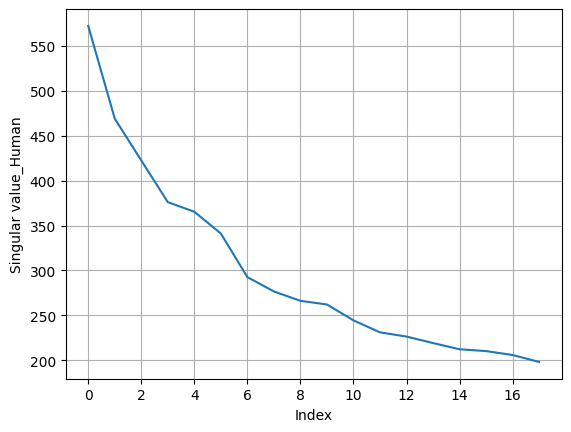

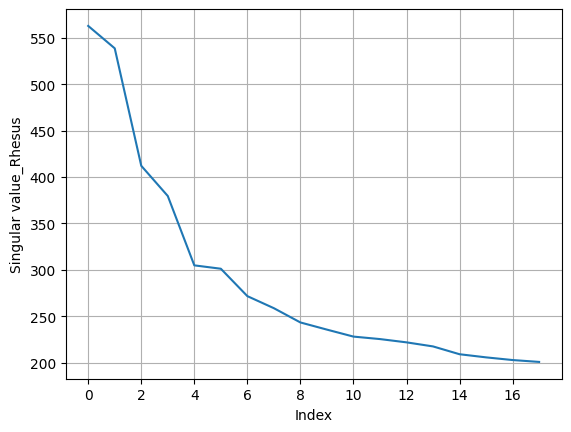

In [17]:
# visualize singular values to select n_components

fig, ax = plt.subplots()
ax.plot(list(range(len(singular_values_human))), singular_values_human)
ax.set(xlabel='Index', ylabel='Singular value_Human')
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid()

fig, ax = plt.subplots()
ax.plot(list(range(len(singular_values_rhesus))), singular_values_rhesus)
ax.set(xlabel='Index', ylabel='Singular value_Rhesus')
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid()

We use this plot to decide how many components to use during matching with overlapping features, similar to the concept used with Elbow plots during PCA reduction. From this plot any value **above 6** looks good, we choose 10 here.

In [18]:
# any value above six looks good; let us choose 12
_ = mario_human.compute_dist_ovlp(n_components=12)
_ = mario_rhesus.compute_dist_ovlp(n_components=12)

# specify how many cells in df1 should be matched to one cell in df2, we use the standard 1cell to 1cell matching
mario_human.specify_matching_params(1)
mario_rhesus.specify_matching_params(1)

**Optional**: We also provide the option to run the **MARIO** matching with sparsity. Running with sparsity could reduce the run time if the data size is large, and potentially be a denoising step. We provide a function find the best sparsity number to use:

In [21]:
# [optional] check the minimum valid sparsity level
mario_human.search_minimum_sparsity(mario_human.dist['ovlp'], slackness=1, init_sparsity=100, verbose=True)

If sparsity>=30000, then there is a valid matching; if sparsity<1, then there is no valid matching.
If sparsity>=30000, then there is a valid matching; if sparsity<101, then there is no valid matching.
If sparsity>=15050, then there is a valid matching; if sparsity<101, then there is no valid matching.
If sparsity>=7575, then there is a valid matching; if sparsity<101, then there is no valid matching.
If sparsity>=3838, then there is a valid matching; if sparsity<101, then there is no valid matching.
If sparsity>=1969, then there is a valid matching; if sparsity<101, then there is no valid matching.
If sparsity>=1035, then there is a valid matching; if sparsity<101, then there is no valid matching.
If sparsity>=568, then there is a valid matching; if sparsity<101, then there is no valid matching.
If sparsity>=568, then there is a valid matching; if sparsity<335, then there is no valid matching.
If sparsity>=568, then there is a valid matching; if sparsity<452, then there is no valid ma

(484, 485)

In [22]:
# [optional] check the minimum valid sparsity level
mario_rhesus.search_minimum_sparsity(mario_rhesus.dist['ovlp'], slackness=1, init_sparsity=100, verbose=True)

If sparsity>=30000, then there is a valid matching; if sparsity<1, then there is no valid matching.
If sparsity>=30000, then there is a valid matching; if sparsity<101, then there is no valid matching.
If sparsity>=15050, then there is a valid matching; if sparsity<101, then there is no valid matching.
If sparsity>=7575, then there is a valid matching; if sparsity<101, then there is no valid matching.
If sparsity>=3838, then there is a valid matching; if sparsity<101, then there is no valid matching.
If sparsity>=1969, then there is a valid matching; if sparsity<101, then there is no valid matching.
If sparsity>=1035, then there is a valid matching; if sparsity<101, then there is no valid matching.
If sparsity>=568, then there is a valid matching; if sparsity<101, then there is no valid matching.
If sparsity>=568, then there is a valid matching; if sparsity<335, then there is no valid matching.
If sparsity>=451, then there is a valid matching; if sparsity<335, then there is no valid ma

(369, 370)

Based on the result, any sparsity level > 104 will give valid matching, thus we will use 120 and perform matching with overlapping features:

*Note: the sparsity value is related (in ratio) to the amount of cells in n1.*

In [19]:
# any a sparsity level >= 104 will give a valid matching 
_ = mario_human.match_cells('ovlp', sparsity=2800, mode='auto')

In [20]:
# any a sparsity level >= 104 will give a valid matching 
_ = mario_rhesus.match_cells('ovlp', sparsity=2800, mode='auto')

**Optional**: If you have the basic annotations of the cell types of the two datasets (the names are the same), we also provides a function that you can do a quick sanity check of how well the matching was:

### Parameters for refined all feature matching:

Then we will start testing how many components to use in the refined matching (which will use all features including non-overlapping features):

In [21]:
# compute distance matrix using all the features
_, canonical_correlations_human = mario_human.compute_dist_all('ovlp', n_components=20)
_, canonical_correlations_rhesus = mario_rhesus.compute_dist_all('ovlp', n_components=20)

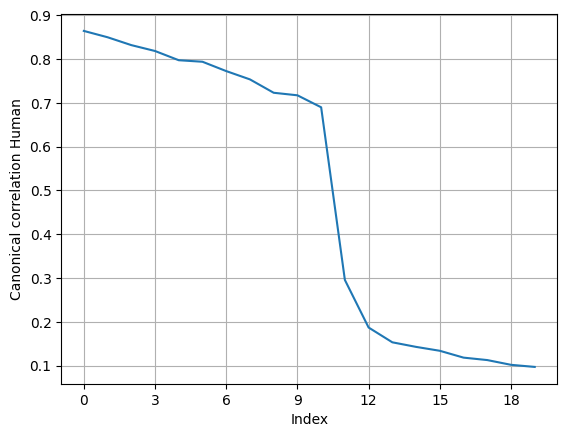

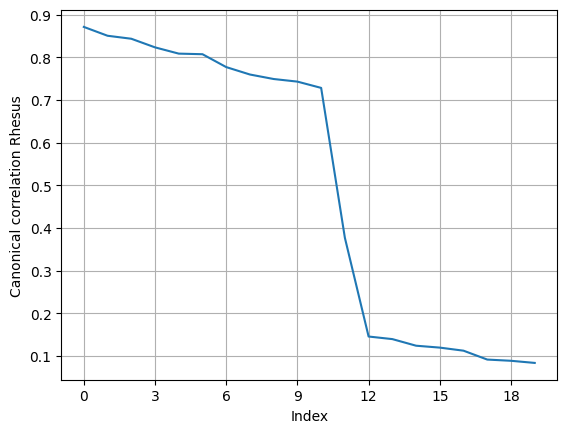

In [22]:
# visualize canonical correlations to select n_components

fig, ax = plt.subplots()
ax.plot(list(range(len(canonical_correlations_human))), canonical_correlations_human)
ax.set(xlabel='Index', ylabel='Canonical correlation Human')
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid()

fig, ax = plt.subplots()
ax.plot(list(range(len(canonical_correlations_rhesus))), canonical_correlations_rhesus)
ax.set(xlabel='Index', ylabel='Canonical correlation Rhesus')
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid()

Based on the plot we can see a steep drop of canonical correlation at 9 components, therefore, we should choose **> 9** components for refined matching, here we choose 12:

In [23]:
_, canonical_correlations_human = mario_human.compute_dist_all('ovlp', n_components=12)
_, canonical_correlations_rhesus = mario_rhesus.compute_dist_all('ovlp', n_components=12)

# perform the refined matching
_ = mario_human.match_cells('all', sparsity=None, mode='auto')
_ = mario_rhesus.match_cells('all', sparsity=None, mode='auto')

**Optional**: Similarly if we have the basic annotations we can test the performance of matching. Note although the increase of accuracy is not significant, the annotation is only very basic and broad, and the matching accuracy will see a larger raise if there is more underlying information hiding in the non-overlapping features/ or the annotations is more specific.

### [Optional] MARIO Matchability test

However, in most cases we don't have an annotation file to quickly validate if the matching of MARIO is solid. Moreover, many datasets should not be forcefully match and integrated (due to underlying biology or poor quality data). Therefore, we provide a rigorous statistical testing to confirm the two dataset can be matched. Note this step could be slow depending on the datasize and parameter selected: 

In [28]:
mario_human.matchable(n_sim=20, top_k=5, flip_prob=0.2, subsample_prop=1, verbose=True)

Random sign flip, round 0...
Random sign flip, round 1...
Random sign flip, round 2...
Random sign flip, round 3...
Random sign flip, round 4...
Random sign flip, round 5...
Random sign flip, round 6...
Random sign flip, round 7...
Random sign flip, round 8...
Random sign flip, round 9...
Random sign flip, round 10...
Random sign flip, round 11...
Random sign flip, round 12...
Random sign flip, round 13...
Random sign flip, round 14...
Random sign flip, round 15...
Random sign flip, round 16...
Random sign flip, round 17...
Random sign flip, round 18...
Random sign flip, round 19...


(0.9, 0.0)

In [29]:
mario_rhesus.matchable(n_sim=20, top_k=5, flip_prob=0.2, subsample_prop=1, verbose=True)

Random sign flip, round 0...
Random sign flip, round 1...
Random sign flip, round 2...
Random sign flip, round 3...
Random sign flip, round 4...
Random sign flip, round 5...
Random sign flip, round 6...
Random sign flip, round 7...
Random sign flip, round 8...
Random sign flip, round 9...
Random sign flip, round 10...
Random sign flip, round 11...
Random sign flip, round 12...
Random sign flip, round 13...
Random sign flip, round 14...
Random sign flip, round 15...
Random sign flip, round 16...
Random sign flip, round 17...
Random sign flip, round 18...
Random sign flip, round 19...


(1.0, 1.0)

The test will give you two p values (#1 for ovlp matching, #2 for all matching). We suggest **not to perform** a matching/integration analysis of any kind on datasets with an average $p > 0.05$.

### Find the best interpolation of overlapping and all matching

Then we can find the best balance between the ```ovlp``` feature matching and ```all``` feature mathcing by the interpolate function. The best weight will be finded and the corresponding match will be stored inside the object:

In [24]:
best_wt, _ = mario_human.interpolate(n_wts=5, top_k=5, verbose=True)

Now at iteration 0, wt=0.0
Now at iteration 1, wt=0.25
Now at iteration 2, wt=0.5
Now at iteration 3, wt=0.75
Now at iteration 4, wt=1.0


In [25]:
best_wt, _ = mario_rhesus.interpolate(n_wts=5, top_k=5, verbose=True)

Now at iteration 0, wt=0.0
Now at iteration 1, wt=0.25
Now at iteration 2, wt=0.5
Now at iteration 3, wt=0.75
Now at iteration 4, wt=1.0


### Joint regularized filtering of sub-optimal matching

At the very last step, we will filter out the potential sub-optimal matching pairs via joint regularized filtering. The filtering will be formed on the matching based on weighted interpolation. The parameter ```n_clusters``` should be approximately be the number of cell populations, and ```n_components``` will be the number of components used during filtering, suggest using number in between the components used during ```ovlp``` and ```all``` matching. The parameter ```bad_prop``` controls the filtering strength and will be more stringent if increased, we suggest using $0.1$ - $0.3$. After filtering, matched cell pairs will be less rows of original data ```df1_sub```.

In [26]:
#Using Seurat-based clustering: human CyTOF dataset has 11 clusters, human QBC dataset has 16 clusters - let's try setting it at 16 clusters
#safer to overcluster
_  = mario_human.filter_bad_matches(
    'wted', n_clusters=16, n_components=10, bad_prop=0.2,
    max_iter=30, tol=1e-5, verbose=True
)

Now at iteration 0, current loss is 46.25381441420688.
Now at iteration 1, current loss is 38.33857950247441.
Now at iteration 2, current loss is 37.29705294950552.
Now at iteration 3, current loss is 36.93451271123782.
Now at iteration 4, current loss is 36.66781235241959.
Now at iteration 5, current loss is 36.52240849606316.
Now at iteration 6, current loss is 36.4434312690831.
Now at iteration 7, current loss is 36.39461984147858.
Now at iteration 8, current loss is 36.34231069821612.
Now at iteration 9, current loss is 36.23633619183935.
Now at iteration 10, current loss is 36.15232101783922.
Now at iteration 11, current loss is 36.12910938095991.
Now at iteration 12, current loss is 36.11806772178575.
Now at iteration 13, current loss is 36.110590053625636.
Now at iteration 14, current loss is 36.102088545983314.
Now at iteration 15, current loss is 36.08826439274266.
Now at iteration 16, current loss is 36.05877862194029.
Now at iteration 17, current loss is 35.98611842581531.
N

In [27]:
#Using Seurat-based clustering: rhesus CyTOF dataset has 13 clusters, rhesus QBC dataset has 13 clusters - let's try setting it at 13 clusters
#safer to overcluster
_  = mario_rhesus.filter_bad_matches(
    'wted', n_clusters=13, n_components=10, bad_prop=0.2,
    max_iter=30, tol=1e-5, verbose=True
)

Now at iteration 0, current loss is 61.14244341055335.
Now at iteration 1, current loss is 56.54989452724779.
Now at iteration 2, current loss is 54.63969362913968.
Now at iteration 3, current loss is 54.25981905378214.
Now at iteration 4, current loss is 54.11155501403944.
Now at iteration 5, current loss is 54.00758247307788.
Now at iteration 6, current loss is 53.91183725251737.
Now at iteration 7, current loss is 53.81993604604029.
Now at iteration 8, current loss is 53.72302806204062.
Now at iteration 9, current loss is 53.600705255535956.
Now at iteration 10, current loss is 53.455874358756766.
Now at iteration 11, current loss is 53.271247156423826.
Now at iteration 12, current loss is 53.22899158506344.
Now at iteration 13, current loss is 53.219355587277214.
Now at iteration 14, current loss is 53.21404070911901.
Now at iteration 15, current loss is 53.21063563604566.
Now at iteration 16, current loss is 53.207659912429506.
Now at iteration 17, current loss is 53.2047177724603

### Matching result access

# All the matching produced by MARIO are stored in object mario.matching and different matching results can be accessed via keys eg. ovlp, all,wted, final. The matching result contains a list of numbers which corresponding of the matching rows (eg. mario.matching['final'][0] is 41, meaning 0th row of df1_sub is matched to 41th row of df2_sub. Empty means match pair being removed after filtering. Here we reformat the matching result to a pd dataframe for checking:

In [28]:
## reformat the MARIO matching results to a dataframe
df_human_rowidx=list(range(len(mario_human.matching['final']))) # extract the final matching
human_filtered_out=[i for i,x in enumerate(mario_human.matching['final']) if not x]
human_match_final_df_CyTOF =[e for e in df_human_rowidx if not e in human_filtered_out]
human_match_final_df_QBC = [item for sublist in mario_human.matching['final'] for item in sublist]
human_matching_final_df = pd.DataFrame(np.column_stack([human_match_final_df_QBC, human_match_final_df_CyTOF]))
human_matching_final_df

#The column assignment in human_matching_final_df (where column 0 corresponds to QBC and column 1 to CyTOF) comes from how MARIO creates the matching pairs.

,0,1
0,11512,0
1,27341,1
2,27944,3
3,1288,7
4,29683,15
...,...,...
10268,14011,29985
10269,11473,29991
10270,13251,29993
10271,17864,29998


In [29]:
## reformat the MARIO matching results to a dataframe
df_rhesus_rowidx=list(range(len(mario_rhesus.matching['final']))) # extract the final matching
rhesus_filtered_out=[i for i,x in enumerate(mario_rhesus.matching['final']) if not x]
rhesus_match_final_df_CyTOF =[e for e in df_rhesus_rowidx if not e in rhesus_filtered_out]
rhesus_match_final_df_QBC = [item for sublist in mario_rhesus.matching['final'] for item in sublist]
rhesus_matching_final_df = pd.DataFrame(np.column_stack([rhesus_match_final_df_QBC, rhesus_match_final_df_CyTOF]))
rhesus_matching_final_df

#The column assignment in human_matching_final_df (where column 0 corresponds to QBC and column 1 to CyTOF) comes from how MARIO creates the matching pairs.

,0,1
0,686,0
1,27155,2
2,18613,3
3,11529,5
4,23650,6
...,...,...
10196,13903,29988
10197,1908,29989
10198,23346,29991
10199,28584,29995


In [30]:
#To compile all matched cells - Human CyTOF
human_cytof_full_30k.iloc[human_matching_final_df.loc[0],]

,CD235a,CD45,CD61,CD7,CD33,CD11c,CD123,CD14,CD11b,CD8,...,pSTAT5(Y694),pTBK1/NAK(S172),pSTAT6(Y691),pPLCg2(Y579),pERK1-2(T202-Y204),pP38-MAPK(T180-Y182),pMAPKAPK2(T334),donor,stimulation,CyTOF_annotation
33579,0.287180,0.822672,0.956753,0.811226,0.456598,0.265259,0.315221,0.489852,0.53489,0.941769,...,0.477199,0.349694,0.417978,0.401786,0.686587,0.476280,0.423555,R26W11_82290,GM-CSF,CD8_T_cells
29929,0.334735,0.809783,0.899267,0.743020,0.322866,0.157195,0.157318,0.429361,0.72245,0.209873,...,0.466287,0.485112,0.355091,0.503329,0.722164,0.582855,0.377301,R20W9_5436,GM-CSF,Naive_T_cells


In [31]:
#To compile all matched cells - Human QBC
human_qbc_full_30k.iloc[human_matching_final_df.loc[0],]

,CD101,CD103,CD105,CD107a,CD112,CD115,CD119,CD11a,CD11b,CD11c,...,KLRG1,LOX.1,Podoplanin,TCR.Va7.2,TCR.Vd2,TCRa.b,TIGIT,integrinB7,QBC_annotation,donor
11512,1.462489,0.122722,0.681088,2.850967,0.527440,0.769081,1.024308,2.817119,1.058534,1.836607,...,0.082784,0.405716,0.773026,0.131286,0.012671,0.337224,0.871138,0.587469,Classical_monocytes,DM
0,1.376394,0.442479,0.744502,1.710150,1.288738,2.094249,1.171319,0.130274,0.286975,0.391543,...,0.691732,1.065257,2.233552,0.183138,0.176681,0.523527,1.018910,1.117167,Non_classical_monocytes,AT


In [32]:
#To compile all matched cells - Rhesus CyTOF
rhesus_cytof_full_30k.iloc[rhesus_matching_final_df.loc[0],]

,CD233,CD45,CD61,CD7,CD33,CD11c,CD123,CD14,CD11b,CD8,...,pSTAT5(Y694),pTBK1/NAK(S172),pSTAT6(Y691),pPLCg2(Y579),pERK1-2(T202-Y204),pP38-MAPK(T180-Y182),pMAPKAPK2(T334),donor,stimulation,CyTOF_annotation
15880,0.242244,0.965658,0.653865,0.925505,0.531104,0.377580,0.204062,0.362283,0.504621,1.008111,...,0.589739,0.433989,0.279181,0.379198,0.346738,0.508463,0.210898,R13W3_D07052,CD40L,CD8_T_cells
20022,0.139914,0.887310,0.657303,0.212592,0.161767,0.087335,0.000000,0.314145,0.405256,0.999004,...,0.612895,0.596322,0.464968,0.579258,0.648231,0.517862,0.526660,R7W11_D07242,CD40L,CD8_T_cells


In [33]:
#To compile all matched cells - Rhesus QBC
rhesus_qbc_full_30k.iloc[rhesus_matching_final_df.loc[0],]

,CD101,CD103,CD105,CD107a,CD112,CD115,CD119,CD11a,CD11b,CD11c,...,KLRG1,LOX.1,Podoplanin,TCR.Va7.2,TCR.Vd2,TCRa.b,TIGIT,integrinB7,QBC_annotation,donor
686,0.748105,0.200979,0.748105,0.848265,0.368246,0.848265,1.171238,1.915092,0.200979,0.000000,...,0.000000,0.511503,0.848265,0.368246,0.000000,0.368246,1.359381,0.748105,B_cells,354
0,1.284431,0.450029,1.070184,1.369519,1.194205,1.088871,2.243316,0.395990,0.467412,0.087709,...,0.501297,1.082681,1.498354,0.426371,0.228472,0.581303,1.279343,0.845535,Non_classical_monocytes,354


**optional**: We also provides the option to do the standard k-NN matching of the MARIO matched pairs:

In [34]:
_ = mario_human.knn_matching('wted', k=5)
_ = mario_rhesus.knn_matching('wted', k=5)

### Joint embedding

# With the cells having high quality pairs, we can use CCA (Canonical Correlation Analysis) to produce the sub-space scores, that can be used for downstream analysis eg. visualization with t-sne/umap, joint clustering and more.

In [35]:
_, cca_human = mario_human.fit_cca(mario_human.matching['final'], n_components=10, max_iter=10000)
human_qbc_mario_30k_sub_cca, human_cytof_mario_30k_sub_cca = cca_human.x_scores_, cca_human.y_scores_

In [36]:
_, cca_rhesus = mario_rhesus.fit_cca(mario_rhesus.matching['final'], n_components=10, max_iter=10000)
rheus_qbc_mario_30k_sub_cca, rhesus_cytof_mario_30k_sub_cca = cca_rhesus.x_scores_, cca_rhesus.y_scores_

Optionally, if we have the labels, we can also quickly check how the matching was performing after filtering, and we will see a furthur increase in matching accuracy:

## 3. Pipeline version MARIO with one line


Previously we have showcased a step-by-step style **MARIO** and parameter screening. For easy impelmentation, we also provide a compact function ```pipelined_mario``` to perform all the steps in **MARIO** in one line. Please note the time and memory usage is directly linked to cell numbers in datasets and should not run locally if matching a total of more than 100k cells. In our tutorial case we are matching the full size datasets and a total of **~30k** cells matching towards **~100k** cells, thus the code chunk could take ~40mins and ~25GB of space (peak). The time and memory usage can be reduced by increasing the ```n_batches``` parameter (inputing smaller cell numbers each iteration and process in stream-line).

Remember you can use the default parameters but **MARIO** will perform better with customized ones. Please refer to our [documentation](https://github.com/shuxiaoc/mario-py/blob/fef06cdfb74017456136741dfeaf61fe0b94b608/src/mario/match.py) inside the package for detailed information.

*Note: although the minimal sparsity level we searched previously was around 100, here the n1 of each batch is around 6k cells, so we roughly made sparsity to 300-400.*

In [37]:
human_final_matching_lst, human_embedding_lst = pipelined_mario(
    data_lst=[human_qbc_mario_30k, human_cytof_mario_30k], 
    normalization=True, 
    n_batches=5,
    n_matched_per_cell=1, 
    sparsity_ovlp=400, 
    sparsity_all=400,
    n_components_ovlp=10, 
    n_components_all=12,
    n_cancor=5, 
    n_wts=4,
    n_clusters=10, 
    n_components_filter=10, 
    bad_prop=0.2, 
    max_iter_filter=20,
    knn=False, 
    embed_dim=10, 
    max_iter_embed=500, 
    save_path='../data', 
    verbose=True
)

Matching data_lst[0] with data_lst[1]
Now at batch 0
Matching using overlapping features...
Matching using all features...
Finding the best interpolated matching...
Now at iteration 0, wt=0.0
Now at iteration 1, wt=0.3333333333333333
Now at iteration 2, wt=0.6666666666666666
Now at iteration 3, wt=1.0
Filtering bad matched pairs...
Now at iteration 0, current loss is 49.048697772112085.
Now at iteration 1, current loss is 44.31338924381002.
Now at iteration 2, current loss is 43.391705708304194.
Now at iteration 3, current loss is 42.78488865855309.
Now at iteration 4, current loss is 42.33742212522223.
Now at iteration 5, current loss is 42.19484518122676.
Now at iteration 6, current loss is 42.04513648509795.
Now at iteration 7, current loss is 41.716970094115624.
Now at iteration 8, current loss is 41.47737099305907.
Now at iteration 9, current loss is 41.42173047332639.
Now at iteration 10, current loss is 41.30868034640312.
Now at iteration 11, current loss is 41.1115964336538.
No

In [38]:
rhesus_final_matching_lst, rhesus_embedding_lst = pipelined_mario(
    data_lst=[rhesus_qbc_mario_30k, rhesus_cytof_mario_30k], 
    normalization=True, 
    n_batches=5,
    n_matched_per_cell=1, 
    sparsity_ovlp=400, 
    sparsity_all=400,
    n_components_ovlp=10, 
    n_components_all=12,
    n_cancor=5, 
    n_wts=4,
    n_clusters=10, 
    n_components_filter=10, 
    bad_prop=0.2, 
    max_iter_filter=20,
    knn=False, 
    embed_dim=10, 
    max_iter_embed=500, 
    save_path='../data', 
    verbose=True
)

Matching data_lst[0] with data_lst[1]
Now at batch 0
Matching using overlapping features...
Matching using all features...
Finding the best interpolated matching...
Now at iteration 0, wt=0.0
Now at iteration 1, wt=0.3333333333333333
Now at iteration 2, wt=0.6666666666666666
Now at iteration 3, wt=1.0
Filtering bad matched pairs...
Now at iteration 0, current loss is 62.785747155806284.
Now at iteration 1, current loss is 60.038475664890704.
Now at iteration 2, current loss is 58.68191089237239.
Now at iteration 3, current loss is 57.93881759663286.
Now at iteration 4, current loss is 57.76505366954642.
Now at iteration 5, current loss is 57.70375669769113.
Now at iteration 6, current loss is 57.675039098433615.
Now at iteration 7, current loss is 57.65365731462435.
Now at iteration 8, current loss is 57.63646014033714.
Now at iteration 9, current loss is 57.619881280443586.
Now at iteration 10, current loss is 57.605654567338206.
Now at iteration 11, current loss is 57.59695343127705.

## 4. Downstream Analysis

After the MARIO matching and integration pipeline, we can perform various downstream analysis. Here we will just do some simple showcase of t-sne visualization. These results are also saved out and are compatible for further analysis with popular packages eg ```scanpy```

First we can make the t-sne plots:

In [39]:
import seaborn as sns
from sklearn.manifold import TSNE

# do t-SNE plotting
tsne = TSNE(n_components=2, verbose=0, perplexity=30, n_iter=1000)

# only use 10 components
human_tsne_results = tsne.fit_transform(np.vstack([human_embedding_lst[0][:,0:10], human_embedding_lst[1][:,0:10]]))
human_embedding_gcca = pd.DataFrame(human_tsne_results, columns = ['tsne1', 'tsne2'])

In [40]:
# do t-SNE plotting
tsne = TSNE(n_components=2, verbose=0, perplexity=30, n_iter=1000)

# only use 10 components
rhesus_tsne_results = tsne.fit_transform(np.vstack([rhesus_embedding_lst[0][:,0:10], rhesus_embedding_lst[1][:,0:10]]))
rhesus_embedding_gcca = pd.DataFrame(rhesus_tsne_results, columns = ['tsne1', 'tsne2'])

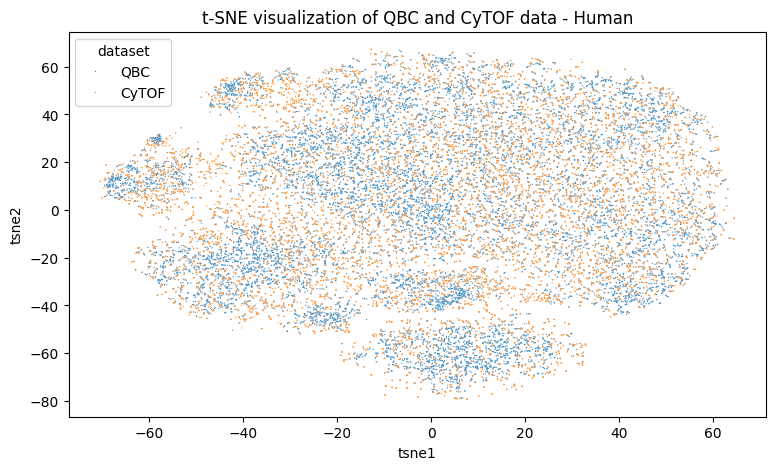

In [41]:
# input labels dataset of origin - human

# Create the DataFrame directly from t-SNE results to ensure matching dimensions
human_embedding_gcca = pd.DataFrame(human_tsne_results, columns=['tsne1', 'tsne2'])

# Now add the dataset labels with matching dimensions
n_samples_qbc = human_embedding_lst[0].shape[0]  # 18168
n_samples_cytof = human_embedding_lst[1].shape[0]  # 18168
human_embedding_gcca['dataset'] = np.repeat(["QBC", "CyTOF"], [n_samples_qbc, n_samples_cytof])

# Create the plot
fig = plt.figure(figsize=(9,5), dpi=100, facecolor='w', edgecolor='k')
sns.scatterplot(data=human_embedding_gcca, x='tsne1', y='tsne2', hue='dataset', s=0.8)
plt.title('t-SNE visualization of QBC and CyTOF data - Human')
plt.savefig('C:/Users/Aaron/Nolan Lab Dropbox/Aaron Tan/QBC/MARIO_CyTOF_and_QBC_single_cell_matching/matching_20_nov_2024/mario_tsne_plot_human.png', 
            dpi=600, 
            bbox_inches='tight',
            facecolor='white',
            edgecolor='none')

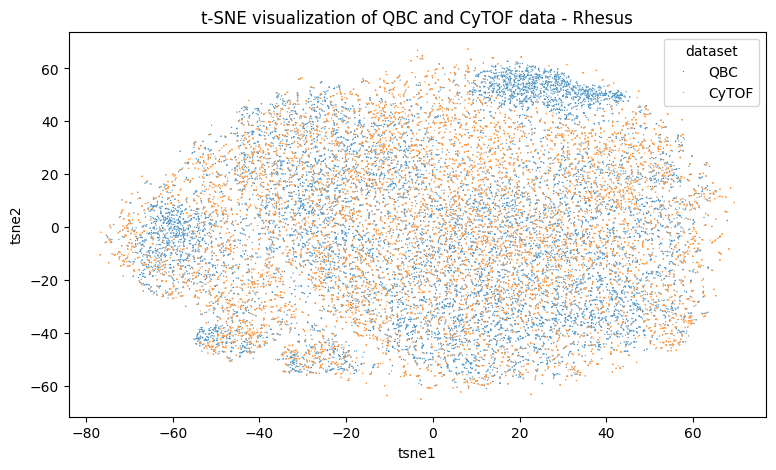

In [42]:
# input labels dataset of origin - rhesus

# Create the DataFrame directly from t-SNE results to ensure matching dimensions
rhesus_embedding_gcca = pd.DataFrame(rhesus_tsne_results, columns=['tsne1', 'tsne2'])

# Now add the dataset labels with matching dimensions
n_samples_qbc = rhesus_embedding_lst[0].shape[0]
n_samples_cytof = rhesus_embedding_lst[1].shape[0]
rhesus_embedding_gcca['dataset'] = np.repeat(["QBC", "CyTOF"], [n_samples_qbc, n_samples_cytof])

# Create the plot
fig = plt.figure(figsize=(9,5), dpi=100, facecolor='w', edgecolor='k')
sns.scatterplot(data=rhesus_embedding_gcca, x='tsne1', y='tsne2', hue='dataset', s=0.8)
plt.title('t-SNE visualization of QBC and CyTOF data - Rhesus')
plt.savefig('C:/Users/Aaron/Nolan Lab Dropbox/Aaron Tan/QBC/MARIO_CyTOF_and_QBC_single_cell_matching/matching_20_nov_2024/mario_tsne_plot_rhesus.png', 
            dpi=600, 
            bbox_inches='tight',
            facecolor='white',
            edgecolor='none')

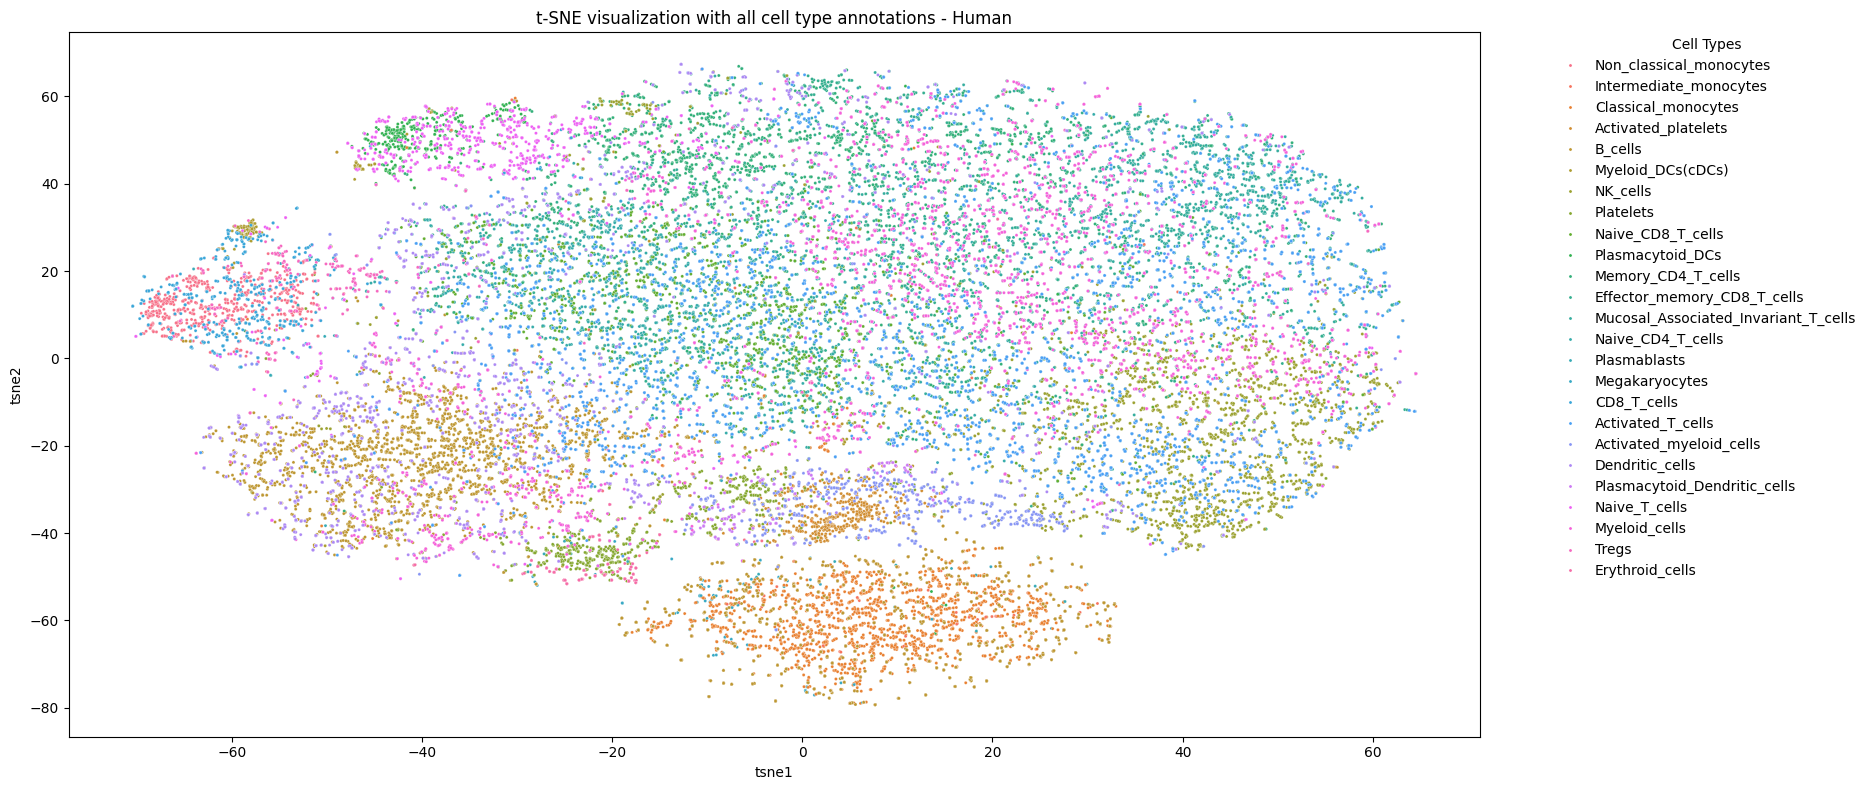

In [43]:
# Color by cell types annotations - Human
# Reformat the MARIO matching results
df_human_rowidx = list(range(len(human_final_matching_lst[1])))
human_filtered_out = [i for i,x in enumerate(human_final_matching_lst[1]) if not x]
human_match_final_df_QBC = [e for e in df_human_rowidx if not e in human_filtered_out]
human_match_final_df_CyTOF = [item for sublist in human_final_matching_lst[1] for item in sublist]
human_matching_final_df = pd.DataFrame(np.column_stack([human_match_final_df_QBC, human_match_final_df_CyTOF]))

# Add annotations to the t-SNE visualization
human_embedding_gcca['annotation'] = np.hstack([
    human_qbc_30k_labels[human_match_final_df_QBC],
    human_cytof_30k_labels[human_match_final_df_CyTOF]
])

# Create and save the plot
fig = plt.figure(figsize=(15,8), dpi=100, facecolor='w', edgecolor='k')

sns.scatterplot(data=human_embedding_gcca, 
                x='tsne1', 
                y='tsne2', 
                hue='annotation', 
                s=5,
                legend='full')
plt.title('t-SNE visualization with all cell type annotations - Human')
plt.tight_layout()
plt.legend(bbox_to_anchor=(1.05, 1), 
          loc='upper left', 
          borderaxespad=0,
          title='Cell Types',
          frameon=False)

# Save the plot
plt.savefig('C:/Users/Aaron/Nolan Lab Dropbox/Aaron Tan/QBC/MARIO_CyTOF_and_QBC_single_cell_matching/matching_20_nov_2024/mario_tsne_plot_cell_type_annotations_human.png', 
            dpi=1800, 
            bbox_inches='tight',
            facecolor='white',
            edgecolor='none')

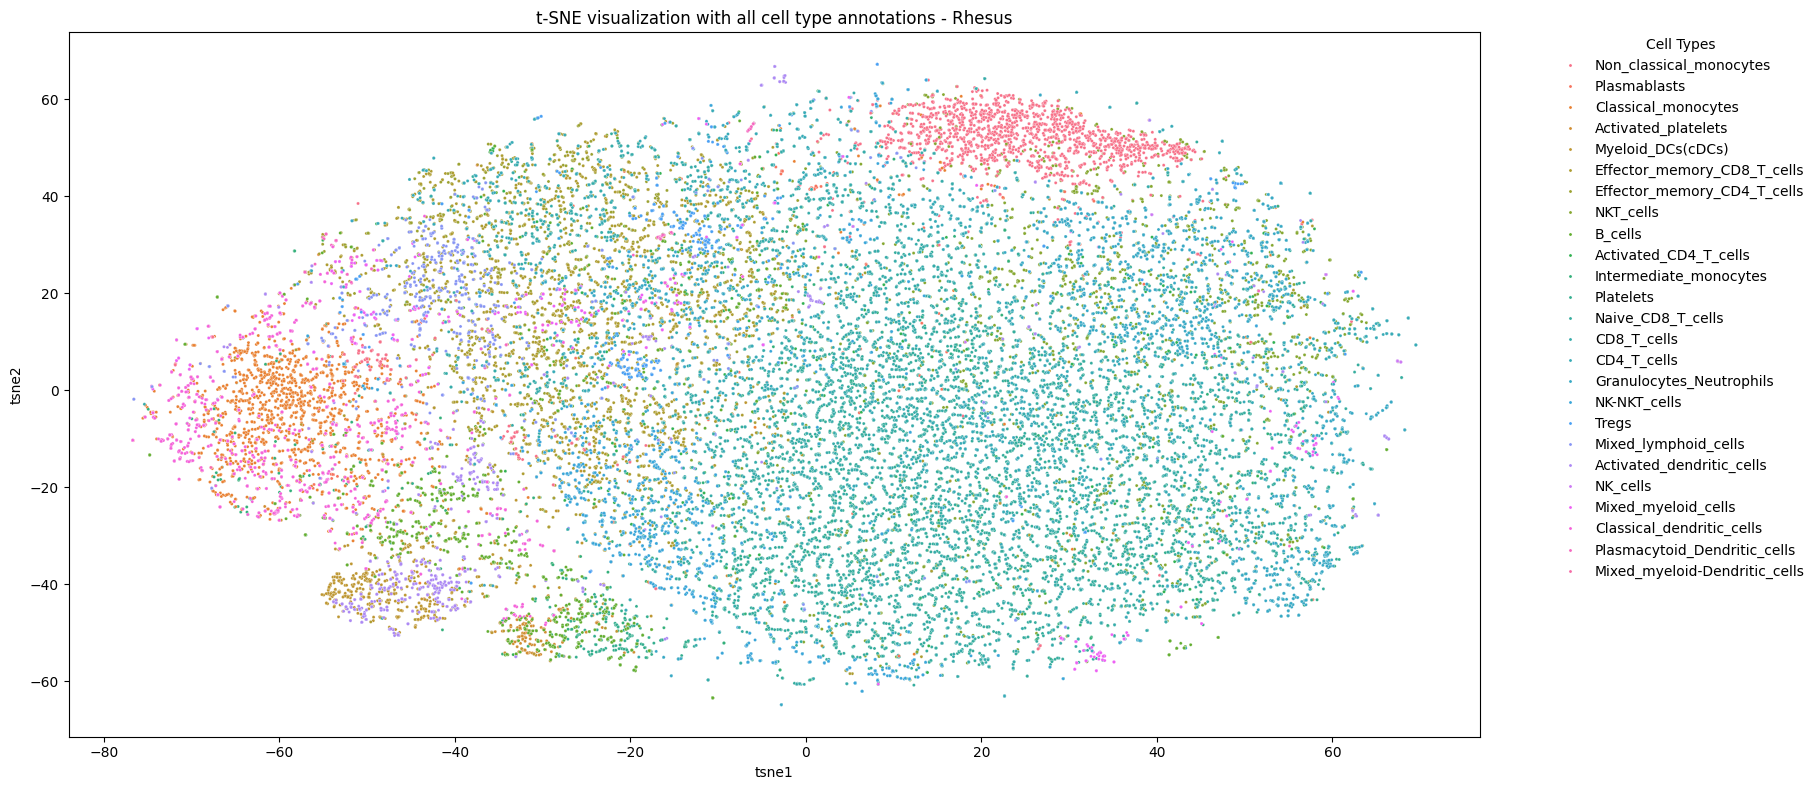

In [44]:
# Color by cell types annotations - Rhesus

# Reformat the MARIO matching results
df_rhesus_rowidx = list(range(len(rhesus_final_matching_lst[1])))
rhesus_filtered_out = [i for i,x in enumerate(rhesus_final_matching_lst[1]) if not x]
rhesus_match_final_df_QBC = [e for e in df_rhesus_rowidx if not e in rhesus_filtered_out]
rhesus_match_final_df_CyTOF = [item for sublist in rhesus_final_matching_lst[1] for item in sublist]
rhesus_matching_final_df = pd.DataFrame(np.column_stack([rhesus_match_final_df_QBC, rhesus_match_final_df_CyTOF]))

# Add annotations to the t-SNE visualization
rhesus_embedding_gcca['annotation'] = np.hstack([
    rhesus_qbc_30k_labels[rhesus_match_final_df_QBC], 
    rhesus_cytof_30k_labels[rhesus_match_final_df_CyTOF]
])

# Create and save the plot
fig = plt.figure(figsize=(15,8), dpi=100, facecolor='w', edgecolor='k')

sns.scatterplot(data=rhesus_embedding_gcca, 
                x='tsne1', 
                y='tsne2', 
                hue='annotation', 
                s=5,
                legend='full')
plt.title('t-SNE visualization with all cell type annotations - Rhesus')
plt.tight_layout()
plt.legend(bbox_to_anchor=(1.05, 1), 
          loc='upper left', 
          borderaxespad=0,
          title='Cell Types',
          frameon=False)

# Save the plot
plt.savefig('C:/Users/Aaron/Nolan Lab Dropbox/Aaron Tan/QBC/MARIO_CyTOF_and_QBC_single_cell_matching/matching_20_nov_2024/mario_tsne_plot_cell_type_annotations_rhesus.png', 
            dpi=1800, 
            bbox_inches='tight',
            facecolor='white',
            edgecolor='none')

In [45]:
human_embedding_gcca.to_csv("C:/Users/Aaron/Nolan Lab Dropbox/Aaron Tan/QBC/MARIO_CyTOF_and_QBC_single_cell_matching/matching_20_nov_2024/human_embedding_gcca.csv")
human_embedding_gcca

,tsne1,tsne2,dataset,annotation
0,-68.008331,12.409739,QBC,Non_classical_monocytes
1,39.472382,15.210166,QBC,Intermediate_monocytes
2,-66.683479,12.899960,QBC,Non_classical_monocytes
3,18.892044,-58.390465,QBC,Classical_monocytes
4,-2.554756,-62.112999,QBC,Classical_monocytes
...,...,...,...,...
33023,27.177773,11.019978,CyTOF,Myeloid_cells
33024,49.669735,-29.972118,CyTOF,Activated_T_cells
33025,51.149101,27.797165,CyTOF,Activated_T_cells
33026,-45.018967,19.126802,CyTOF,Tregs


In [46]:
rhesus_embedding_gcca.to_csv("C:/Users/Aaron/Nolan Lab Dropbox/Aaron Tan/QBC/MARIO_CyTOF_and_QBC_single_cell_matching/matching_20_nov_2024/rhesus_embedding_gcca.csv")
rhesus_embedding_gcca

,tsne1,tsne2,dataset,annotation
0,20.795986,50.048702,QBC,Non_classical_monocytes
1,34.899349,51.678852,QBC,Non_classical_monocytes
2,34.946598,51.478542,QBC,Non_classical_monocytes
3,43.481998,49.833904,QBC,Non_classical_monocytes
4,23.855146,55.375584,QBC,Non_classical_monocytes
...,...,...,...,...
30459,54.166851,-46.624516,CyTOF,Granulocytes_Neutrophils
30460,-4.212792,3.860485,CyTOF,CD4_T_cells
30461,22.795717,-27.238657,CyTOF,CD8_T_cells
30462,-23.246643,-1.656243,CyTOF,Mixed_lymphoid_cells


In [47]:
#Export matched human QBC cells
matched_QBC_human_input = human_qbc_full_30k.iloc[human_match_final_df_QBC,]
matched_QBC_human_tsnvalue = human_embedding_gcca.iloc[:matched_QBC_human_input.shape[0],]

#bind both dataframes of matched cells together with the tsne values of matching
df_matched_QBC_human = pd.concat([matched_QBC_human_input.reset_index(drop=True), matched_QBC_human_tsnvalue.reset_index(drop=True)], axis=1)

df_matched_QBC_human.to_csv("C:/Users/Aaron/Nolan Lab Dropbox/Aaron Tan/QBC/MARIO_CyTOF_and_QBC_single_cell_matching/matching_20_nov_2024/df_matched_QBC_human.csv", index=True)

df_matched_QBC_human

,CD101,CD103,CD105,CD107a,CD112,CD115,CD119,CD11a,CD11b,CD11c,...,TCR.Vd2,TCRa.b,TIGIT,integrinB7,QBC_annotation,donor,tsne1,tsne2,dataset,annotation
0,1.388429,0.415911,0.770312,1.716389,1.305763,2.166499,1.270200,0.173204,0.295527,0.256392,...,0.194659,0.320791,1.037560,1.168676,Non_classical_monocytes,AT,-68.008331,12.409739,QBC,Non_classical_monocytes
1,1.800869,0.197914,0.785328,2.448304,0.534147,0.570715,1.850899,2.232554,0.302322,0.673021,...,0.054942,0.415663,0.829410,1.332015,Intermediate_monocytes,AT,39.472382,15.210166,QBC,Intermediate_monocytes
2,1.543894,0.417856,0.740947,1.068344,1.332985,1.611695,1.074266,0.793131,0.309755,0.383105,...,0.090842,0.316078,0.872068,1.117604,Non_classical_monocytes,AT,-66.683479,12.899960,QBC,Non_classical_monocytes
3,1.463329,0.168277,0.736592,2.502375,0.678147,0.815935,1.409506,2.377478,0.472310,1.450774,...,0.092599,0.296370,0.621877,0.720988,Classical_monocytes,AT,18.892044,-58.390465,QBC,Classical_monocytes
4,1.507514,0.228083,0.805695,1.754786,1.057348,0.676930,1.067187,2.459849,0.545732,1.617824,...,0.120530,0.413684,0.705451,0.654993,Classical_monocytes,AT,-2.554756,-62.112999,QBC,Classical_monocytes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16509,1.572390,0.478821,0.667037,3.185167,0.629030,1.313688,2.030172,3.135070,-0.004541,0.205743,...,0.020823,0.308135,0.957475,1.441442,Effector_memory_CD8_T_cells,YH,22.346363,10.603920,QBC,Effector_memory_CD8_T_cells
16510,0.582992,0.262847,0.827548,3.401009,0.214689,0.547602,1.936880,3.243506,0.412736,0.596479,...,0.020224,0.103625,1.173311,1.046592,NK_cells,YH,49.043255,-30.703665,QBC,NK_cells
16511,0.769998,0.084742,0.402757,2.322620,0.457017,0.691919,1.826931,3.289748,0.048857,0.616704,...,0.043560,0.302802,1.171857,1.533915,NK_cells,YH,39.675865,7.745970,QBC,NK_cells
16512,1.250636,0.333743,0.903156,2.072329,0.513587,0.541240,1.975423,1.766406,0.167745,0.245925,...,0.009337,0.374683,1.292690,0.859906,Naive_CD4_T_cells,YH,-44.356052,18.642048,QBC,Naive_CD4_T_cells


In [48]:
#Export matched human CyTOF cells
matched_CyTOF_human_input = human_cytof_full_30k.iloc[human_match_final_df_CyTOF,]
matched_CyTOF_human_tsnvalue = human_embedding_gcca.iloc[:matched_CyTOF_human_input.shape[0],]

#bind both dataframes of matched cells together with the tsne values of matching
df_matched_CyTOF_human = pd.concat([matched_CyTOF_human_input.reset_index(drop=True), matched_CyTOF_human_tsnvalue.reset_index(drop=True)], axis=1)

df_matched_CyTOF_human.to_csv("C:/Users/Aaron/Nolan Lab Dropbox/Aaron Tan/QBC/MARIO_CyTOF_and_QBC_single_cell_matching/matching_20_nov_2024/df_matched_CyTOF_human.csv", index=True)

df_matched_CyTOF_human

,CD235a,CD45,CD61,CD7,CD33,CD11c,CD123,CD14,CD11b,CD8,...,pERK1-2(T202-Y204),pP38-MAPK(T180-Y182),pMAPKAPK2(T334),donor,stimulation,CyTOF_annotation,tsne1,tsne2,dataset,annotation
0,0.279173,0.834441,0.886521,0.792472,0.425783,0.180326,0.239236,0.417438,0.533845,0.892605,...,0.728918,0.630605,0.505046,R21W3_6054,CD40L,CD8_T_cells,-68.008331,12.409739,QBC,Non_classical_monocytes
1,0.478829,0.835520,0.706719,0.016058,0.640695,0.620276,0.122523,0.370834,1.125864,0.058993,...,0.839508,0.417694,0.432868,R20W3_7605,Basal,Activated_T_cells,39.472382,15.210166,QBC,Intermediate_monocytes
2,0.322483,0.682491,0.996241,0.700559,0.586917,0.162929,0.339025,0.410281,0.683493,0.907800,...,0.702862,0.590436,0.386512,R21W9_5656,CD40L,CD8_T_cells,-66.683479,12.899960,QBC,Non_classical_monocytes
3,0.271295,0.998863,0.849111,0.066406,0.440530,0.239659,0.428758,0.437153,0.644982,0.131877,...,0.552251,0.637478,0.314989,R24W1_6093,CD40L,B_cells,18.892044,-58.390465,QBC,Classical_monocytes
4,0.206088,0.743371,0.999302,0.567653,0.675722,0.225603,0.387798,0.357729,0.707649,0.458193,...,0.598942,0.437218,0.447384,R19W1_6955,Basal,B_cells,-2.554756,-62.112999,QBC,Classical_monocytes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16509,0.360861,0.953144,0.779857,0.201581,0.544191,0.525152,0.371061,0.615938,1.171719,0.343411,...,0.870396,0.528715,0.450991,R18W11_5440,GM-CSF,Myeloid_cells,22.346363,10.603920,QBC,Effector_memory_CD8_T_cells
16510,0.275741,0.767642,0.436546,0.174095,0.497776,0.575447,0.065610,0.361393,0.989449,0.145209,...,0.874458,0.602625,0.485635,R15W9_W070515101352,CD40L,Activated_T_cells,49.043255,-30.703665,QBC,NK_cells
16511,0.501819,0.741718,0.861548,0.240843,0.669034,0.430169,0.375740,0.444202,1.025399,0.260094,...,0.821818,0.524748,0.516520,R21W3_6054,CD40L,Activated_T_cells,39.675865,7.745970,QBC,NK_cells
16512,0.380327,1.067488,0.935008,1.077691,0.418871,0.504148,0.018820,0.222538,0.944037,0.051552,...,0.597523,0.383757,0.299354,R16W11_7826,Basal,Tregs,-44.356052,18.642048,QBC,Naive_CD4_T_cells


In [49]:
#Export matched rhesus QBC cells
matched_QBC_rhesus_input = rhesus_qbc_full_30k.iloc[rhesus_match_final_df_QBC,]
matched_QBC_rhesus_tsnvalue = rhesus_embedding_gcca.iloc[:matched_QBC_rhesus_input.shape[0],]

#bind both dataframes of matched cells together with the tsne values of matching
df_matched_QBC_rhesus = pd.concat([matched_QBC_rhesus_input.reset_index(drop=True), matched_QBC_rhesus_tsnvalue.reset_index(drop=True)], axis=1)

df_matched_QBC_rhesus.to_csv("C:/Users/Aaron/Nolan Lab Dropbox/Aaron Tan/QBC/MARIO_CyTOF_and_QBC_single_cell_matching/matching_20_nov_2024/df_matched_QBC_rhesus.csv", index=True)

df_matched_QBC_rhesus

,CD101,CD103,CD105,CD107a,CD112,CD115,CD119,CD11a,CD11b,CD11c,...,TCR.Vd2,TCRa.b,TIGIT,integrinB7,QBC_annotation,donor,tsne1,tsne2,dataset,annotation
0,1.284431,0.450029,1.070184,1.369519,1.194205,1.088871,2.243316,0.395990,0.467412,0.087709,...,0.228472,0.581303,1.279343,0.845535,Non_classical_monocytes,354,20.795986,50.048702,QBC,Non_classical_monocytes
1,1.223363,0.482928,1.121475,1.320857,1.247967,1.215025,2.122944,0.366097,0.319363,0.081263,...,0.218784,0.555662,1.279858,0.887789,Non_classical_monocytes,354,34.899349,51.678852,QBC,Non_classical_monocytes
2,1.222409,0.463499,1.246537,1.305673,1.241225,1.104472,2.050463,0.713469,0.397624,0.062496,...,0.251226,0.623805,1.246537,0.938828,Non_classical_monocytes,354,34.946598,51.478542,QBC,Non_classical_monocytes
3,1.063220,0.538938,1.575973,1.044781,1.183565,1.303022,1.572319,0.401295,0.646141,0.092568,...,0.346708,0.831219,1.231016,0.738752,Non_classical_monocytes,354,43.481998,49.833904,QBC,Non_classical_monocytes
4,1.274648,0.392627,1.120936,1.400766,1.124066,1.124066,2.121978,1.001184,0.392627,0.100561,...,0.191926,0.537476,1.266551,0.852893,Non_classical_monocytes,354,23.855146,55.375584,QBC,Non_classical_monocytes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15227,0.073981,0.521537,0.996696,1.231414,0.996484,0.529377,1.462575,0.688021,-0.087282,-0.002748,...,0.229230,0.125777,1.050445,0.518774,Naive_CD8_T_cells,356,45.934402,-39.091808,QBC,Naive_CD8_T_cells
15228,0.662725,0.411027,0.792464,0.779374,0.482810,0.894334,1.481882,1.131284,0.042962,0.005689,...,0.017096,0.132006,0.983726,0.482795,Platelets,356,-11.586978,16.103365,QBC,Platelets
15229,0.726471,-0.062990,0.767947,1.106884,0.378009,0.178822,0.965513,1.475348,-0.074646,-0.001747,...,0.296644,-0.128485,0.804237,0.258730,Platelets,356,-12.024688,-5.153080,QBC,Platelets
15230,0.124258,0.278199,1.191800,1.329732,-0.056922,0.728390,1.206081,2.441645,0.289695,0.030166,...,0.026623,0.312851,0.486165,0.953393,Effector_memory_CD8_T_cells,356,-6.193328,24.938023,QBC,Effector_memory_CD8_T_cells


In [50]:
#Export matched rhesus CyTOF cells
matched_CyTOF_rhesus_input = rhesus_cytof_full_30k.iloc[rhesus_match_final_df_CyTOF,]
matched_CyTOF_rhesus_tsnvalue = rhesus_embedding_gcca.iloc[:matched_CyTOF_rhesus_input.shape[0],]

#bind both dataframes of matched cells together with the tsne values of matching
df_matched_CyTOF_rhesus = pd.concat([matched_CyTOF_rhesus_input.reset_index(drop=True), matched_CyTOF_rhesus_tsnvalue.reset_index(drop=True)], axis=1)

df_matched_CyTOF_rhesus.to_csv("C:/Users/Aaron/Nolan Lab Dropbox/Aaron Tan/QBC/MARIO_CyTOF_and_QBC_single_cell_matching/matching_20_nov_2024/df_matched_CyTOF_rhesus.csv", index=True)

df_matched_CyTOF_rhesus

,CD233,CD45,CD61,CD7,CD33,CD11c,CD123,CD14,CD11b,CD8,...,pERK1-2(T202-Y204),pP38-MAPK(T180-Y182),pMAPKAPK2(T334),donor,stimulation,CyTOF_annotation,tsne1,tsne2,dataset,annotation
0,0.816369,0.831481,0.769010,0.748374,0.219402,0.059884,0.398922,0.303959,0.611017,1.012045,...,0.508060,0.417574,0.323444,R13W3_D07052,CD40L,CD8_T_cells,20.795986,50.048702,QBC,Non_classical_monocytes
1,0.782520,0.766513,0.963516,0.564867,0.324602,0.045597,0.327233,0.204017,0.492686,0.344651,...,0.684847,0.529679,0.542809,R7W11_D07242,GM-CSF,CD4_T_cells,34.899349,51.678852,QBC,Non_classical_monocytes
2,0.782520,0.766513,0.963516,0.564867,0.324602,0.045597,0.327233,0.204017,0.492686,0.344651,...,0.684847,0.529679,0.542809,R7W11_D07242,GM-CSF,CD4_T_cells,34.946598,51.478542,QBC,Non_classical_monocytes
3,0.005181,0.821340,0.786055,0.297255,0.613325,0.037313,0.263729,0.295462,0.658279,0.419380,...,0.668987,0.543927,0.427221,R9W7_D07212,CD40L,CD4_T_cells,43.481998,49.833904,QBC,Non_classical_monocytes
4,0.502109,0.850524,0.831471,0.638728,0.470034,0.321360,0.178812,0.439542,0.588415,0.360414,...,0.636838,0.613478,0.519914,R9W7_D07212,Basal,CD4_T_cells,23.855146,55.375584,QBC,Non_classical_monocytes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15227,0.053021,0.916061,0.795750,0.088647,0.566368,0.000000,0.072081,0.673084,1.372442,0.188058,...,0.912439,0.519935,0.099723,R4W9_D06022,CD40L,Granulocytes_Neutrophils,45.934402,-39.091808,QBC,Naive_CD8_T_cells
15228,0.145726,0.904039,0.199887,0.602867,0.141055,0.271397,0.298864,0.383169,0.624686,0.315598,...,0.348557,0.573016,0.172612,R12W7_D07132,Basal,CD4_T_cells,-11.586978,16.103365,QBC,Platelets
15229,0.152258,0.877992,0.952191,0.401486,0.253278,0.154050,0.028155,0.295824,0.468283,0.896112,...,0.471349,0.464401,0.156244,R8W11_D07142,CD40L,CD8_T_cells,-12.024688,-5.153080,QBC,Platelets
15230,0.000000,0.679471,0.545178,0.774236,0.464696,0.142184,0.251895,0.555648,0.624689,1.032128,...,0.207108,0.213078,0.192397,R11W3_D07112,GM-CSF,Mixed_lymphoid_cells,-6.193328,24.938023,QBC,Effector_memory_CD8_T_cells


In [51]:
#Bind both matched CyTOF and matched QBC dataframes/datasets together using the same tsne1 and tsne2 values - Human
combined_df_QBC_CyTOF_human = pd.concat([df_matched_QBC_human, df_matched_CyTOF_human], axis=1)
combined_df_QBC_CyTOF_human.to_csv("C:/Users/Aaron/Nolan Lab Dropbox/Aaron Tan/QBC/MARIO_CyTOF_and_QBC_single_cell_matching/matching_20_nov_2024/combined_df_QBC_CyTOF_human.csv", index=True)
combined_df_QBC_CyTOF_human

#open csv file to manually delete the repeated columns: "tsne1", "tsne2", "dataset" X2, "annotation", columns
#open csv files to manually change 1st "donor" to "QBC donor" and 2nd "donor" to "CyTOF_donor"

,CD101,CD103,CD105,CD107a,CD112,CD115,CD119,CD11a,CD11b,CD11c,...,pERK1-2(T202-Y204),pP38-MAPK(T180-Y182),pMAPKAPK2(T334),donor,stimulation,CyTOF_annotation,tsne1,tsne2,dataset,annotation
0,1.388429,0.415911,0.770312,1.716389,1.305763,2.166499,1.270200,0.173204,0.295527,0.256392,...,0.728918,0.630605,0.505046,R21W3_6054,CD40L,CD8_T_cells,-68.008331,12.409739,QBC,Non_classical_monocytes
1,1.800869,0.197914,0.785328,2.448304,0.534147,0.570715,1.850899,2.232554,0.302322,0.673021,...,0.839508,0.417694,0.432868,R20W3_7605,Basal,Activated_T_cells,39.472382,15.210166,QBC,Intermediate_monocytes
2,1.543894,0.417856,0.740947,1.068344,1.332985,1.611695,1.074266,0.793131,0.309755,0.383105,...,0.702862,0.590436,0.386512,R21W9_5656,CD40L,CD8_T_cells,-66.683479,12.899960,QBC,Non_classical_monocytes
3,1.463329,0.168277,0.736592,2.502375,0.678147,0.815935,1.409506,2.377478,0.472310,1.450774,...,0.552251,0.637478,0.314989,R24W1_6093,CD40L,B_cells,18.892044,-58.390465,QBC,Classical_monocytes
4,1.507514,0.228083,0.805695,1.754786,1.057348,0.676930,1.067187,2.459849,0.545732,1.617824,...,0.598942,0.437218,0.447384,R19W1_6955,Basal,B_cells,-2.554756,-62.112999,QBC,Classical_monocytes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16509,1.572390,0.478821,0.667037,3.185167,0.629030,1.313688,2.030172,3.135070,-0.004541,0.205743,...,0.870396,0.528715,0.450991,R18W11_5440,GM-CSF,Myeloid_cells,22.346363,10.603920,QBC,Effector_memory_CD8_T_cells
16510,0.582992,0.262847,0.827548,3.401009,0.214689,0.547602,1.936880,3.243506,0.412736,0.596479,...,0.874458,0.602625,0.485635,R15W9_W070515101352,CD40L,Activated_T_cells,49.043255,-30.703665,QBC,NK_cells
16511,0.769998,0.084742,0.402757,2.322620,0.457017,0.691919,1.826931,3.289748,0.048857,0.616704,...,0.821818,0.524748,0.516520,R21W3_6054,CD40L,Activated_T_cells,39.675865,7.745970,QBC,NK_cells
16512,1.250636,0.333743,0.903156,2.072329,0.513587,0.541240,1.975423,1.766406,0.167745,0.245925,...,0.597523,0.383757,0.299354,R16W11_7826,Basal,Tregs,-44.356052,18.642048,QBC,Naive_CD4_T_cells


In [52]:
#Bind both matched CyTOF and matched QBC dataframes/datasets together using the same tsne1 and tsne2 values - Rhesus
combined_df_QBC_CyTOF_rhesus = pd.concat([df_matched_QBC_rhesus, df_matched_CyTOF_rhesus], axis=1)
combined_df_QBC_CyTOF_rhesus.to_csv("C:/Users/Aaron/Nolan Lab Dropbox/Aaron Tan/QBC/MARIO_CyTOF_and_QBC_single_cell_matching/matching_20_nov_2024/combined_df_QBC_CyTOF_rhesus.csv", index=True)
combined_df_QBC_CyTOF_rhesus

#open csv file to manually delete the repeated columns: "tsne1", "tsne2", "dataset" X2, "annotation", columns
#open csv files to manually change 1st "donor" to "QBC donor" and 2nd "donor" to "CyTOF_donor"

,CD101,CD103,CD105,CD107a,CD112,CD115,CD119,CD11a,CD11b,CD11c,...,pERK1-2(T202-Y204),pP38-MAPK(T180-Y182),pMAPKAPK2(T334),donor,stimulation,CyTOF_annotation,tsne1,tsne2,dataset,annotation
0,1.284431,0.450029,1.070184,1.369519,1.194205,1.088871,2.243316,0.395990,0.467412,0.087709,...,0.508060,0.417574,0.323444,R13W3_D07052,CD40L,CD8_T_cells,20.795986,50.048702,QBC,Non_classical_monocytes
1,1.223363,0.482928,1.121475,1.320857,1.247967,1.215025,2.122944,0.366097,0.319363,0.081263,...,0.684847,0.529679,0.542809,R7W11_D07242,GM-CSF,CD4_T_cells,34.899349,51.678852,QBC,Non_classical_monocytes
2,1.222409,0.463499,1.246537,1.305673,1.241225,1.104472,2.050463,0.713469,0.397624,0.062496,...,0.684847,0.529679,0.542809,R7W11_D07242,GM-CSF,CD4_T_cells,34.946598,51.478542,QBC,Non_classical_monocytes
3,1.063220,0.538938,1.575973,1.044781,1.183565,1.303022,1.572319,0.401295,0.646141,0.092568,...,0.668987,0.543927,0.427221,R9W7_D07212,CD40L,CD4_T_cells,43.481998,49.833904,QBC,Non_classical_monocytes
4,1.274648,0.392627,1.120936,1.400766,1.124066,1.124066,2.121978,1.001184,0.392627,0.100561,...,0.636838,0.613478,0.519914,R9W7_D07212,Basal,CD4_T_cells,23.855146,55.375584,QBC,Non_classical_monocytes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15227,0.073981,0.521537,0.996696,1.231414,0.996484,0.529377,1.462575,0.688021,-0.087282,-0.002748,...,0.912439,0.519935,0.099723,R4W9_D06022,CD40L,Granulocytes_Neutrophils,45.934402,-39.091808,QBC,Naive_CD8_T_cells
15228,0.662725,0.411027,0.792464,0.779374,0.482810,0.894334,1.481882,1.131284,0.042962,0.005689,...,0.348557,0.573016,0.172612,R12W7_D07132,Basal,CD4_T_cells,-11.586978,16.103365,QBC,Platelets
15229,0.726471,-0.062990,0.767947,1.106884,0.378009,0.178822,0.965513,1.475348,-0.074646,-0.001747,...,0.471349,0.464401,0.156244,R8W11_D07142,CD40L,CD8_T_cells,-12.024688,-5.153080,QBC,Platelets
15230,0.124258,0.278199,1.191800,1.329732,-0.056922,0.728390,1.206081,2.441645,0.289695,0.030166,...,0.207108,0.213078,0.192397,R11W3_D07112,GM-CSF,Mixed_lymphoid_cells,-6.193328,24.938023,QBC,Effector_memory_CD8_T_cells


In [ ]:
##Plot UMAP by stimulation conditions 
##Plot UMAP by donors

Other downstream analysis related to the matching result can be performed either.